<a href="https://colab.research.google.com/github/ltittle/QNC/blob/main/Fitting_the_LATER_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Fitted parameters:
  muR     = 6.7114
  deltaS  = 2.3226
  NLL     = 115.2539


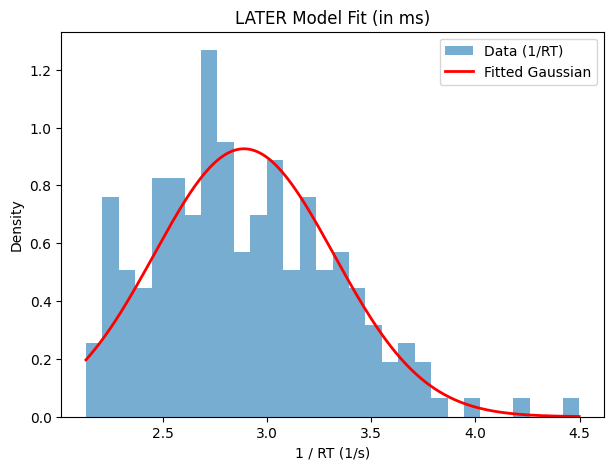

In [3]:

import numpy as np
from scipy.optimize import minimize
from scipy.stats import norm
import matplotlib.pyplot as plt

#Remember 1/RT is assumed to be gaussian.
# 1. Simulate data (in milliseconds)

# Here we simulate sample RT data (real data would be loaded instead but this is in python not using the matlab file)

np.random.seed(0) #set to 0 to help with debugging. Setting it allows for the numbers you have to be repeatable
RTs_ms = np.random.normal(350, 50, 200)  # Generates 200 RTs and the mean is 350 ms, std 50 ms
RTs_ms = RTs_ms[RTs_ms > 100]  # remove unrealistic outliers (i.e. reaction times that just wouldn't happen)

# Convert to seconds for model fitting (optional, just for convention)
RTs = RTs_ms / 1000  #this will give you all of your RTs in seconds by dividing by 1000


# 2. Define the objective function (negative log-likelihood)
def later_nll(params, RTs):
    muR, deltaS = params
    # enforce positivity
    if muR <= 0 or deltaS <= 0:
        return np.inf
        #this returns the negative log-likelihoods: lower NLL = better fit model btw. Remember logs turn multiplications into additions/squishes the data so it's more interpretable.


    # Transform LATER params into Gaussian parameters
    mu = muR / deltaS #mean rate of rise for a decision
    sigma = 1 / deltaS #standard deviation of the slope
    #mu and sigma are the mean and SD of the slope for the gaussian distribution of reciprocal reaction times.

    invRT = 1 / RTs #array of reaction times in s bc we used RTs_ms / 1000 above
    #invRT just stores the reaction times so now we can use them below to compute the negative NLL.

    # Compute negative log-likelihoods
    nll = -np.sum(norm.logpdf(invRT, loc=mu, scale=sigma))
    return nll
    #bigger NLL = worse fit


# 3. Define initial values and parameter bounds

# Hints for initial values:
#   - mean(1/RT) ~ mu
#   - std(1/RT)  ~ sigma
#   - muR = mu / sigma
#   - deltaS = 1 / sigma

invRT = 1 / RTs #inverted RTs here
mu_emp = np.mean(invRT) #compute mu and sigma (of slope)
sigma_emp = np.std(invRT)

initial_muR = mu_emp / sigma_emp #convert so that we can have a starting point for the model parameters.
initial_deltaS = 1 / sigma_emp
initial_values = np.array([initial_muR, initial_deltaS]) #put values into array

bounds = [(0.001, 1000), (0.001, 1000)] #define bounds


# 4. Fit the model (using SciPy's minimize)

result = minimize(later_nll, initial_values, args=(RTs,),
                  bounds=bounds, method='L-BFGS-B')

muR_fit, deltaS_fit = result.x #extract fitted parameters
nll_fit = result.fun #gives you the NLL at the fitted parameter

print("Fitted parameters:")
print(f"  muR     = {muR_fit:.4f}")
print(f"  deltaS  = {deltaS_fit:.4f}")
print(f"  NLL     = {nll_fit:.4f}")

# 5. Evaluate and visualize the fit

mu_fit = muR_fit / deltaS_fit
sigma_fit = 1 / deltaS_fit

# Plot histogram of 1/RT and fitted Gaussian
x = np.linspace(np.min(1/RTs), np.max(1/RTs), 200)
pdf_fit = norm.pdf(x, loc=mu_fit, scale=sigma_fit)

plt.figure(figsize=(7, 5))
plt.hist(1/RTs, bins=30, density=True, alpha=0.6, label='Data (1/RT)')
plt.plot(x, pdf_fit, 'r-', lw=2, label='Fitted Gaussian')
plt.xlabel('1 / RT (1/s)')
plt.ylabel('Density')
plt.legend()
plt.title('LATER Model Fit (in ms)')
plt.show()
